# 02 · Flash separations

The simplest separator is a vessel: heat a liquid, drop the pressure, and let vapour and liquid part company
once. The flash sets the vocabulary - bubble and dew points, K-values, the Rachford-Rice equation - that
every stage of every column reuses. This notebook solves isothermal and adiabatic flashes for binary and
multicomponent mixtures, and shows what one stage can and cannot do.

**What you will learn**
- compute bubble and dew points of multicomponent mixtures
- solve the Rachford-Rice equation
- understand the recovery-purity trade-off of a single stage
- solve an adiabatic flash

**Before you start:** notebook 01  ·  **Time:** about 60 min

In [1]:
try:                      # on Google Colab (or anywhere engsep is missing): install it from GitHub
    import engsep
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engsep"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engsep import flash, vle
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## Bubble and dew points of a mixture

In [2]:
names, z = ["n-butane", "n-pentane", "n-hexane"], [0.3, 0.4, 0.3]
P = 2e5
Tb, Td = flash.bubble_point_T(names, z, P), flash.dew_point_T(names, z, P)
print(f"C4/C5/C6 30/40/30 at 2 bar: bubble point {Tb-273.15:.1f} degC, dew point {Td-273.15:.1f} degC")
print("K-values at the bubble point:", {n: round(vle.k_value(n, Tb, P), 3) for n in names})

C4/C5/C6 30/40/30 at 2 bar: bubble point 45.4 degC, dew point 67.4 degC
K-values at the bubble point: {'n-butane': 2.184, 'n-pentane': 0.69, 'n-hexane': 0.229}


Between the bubble point (the first bubble of vapour) and the dew point (the last drop of liquid) the
mixture is two-phase. K-values $y_i/x_i$ - vapour pressure over total pressure for an ideal mixture - are
above one for the lights and below one for the heavies; a component with K = 1 does not separate at all.

## The Rachford-Rice equation

flash at 56.4 degC: V/F = 0.469
component   z     K  x (liquid)  y (vapour)
 n-butane 0.3 2.896       0.159       0.460
n-pentane 0.4 0.967       0.406       0.393
 n-hexane 0.3 0.338       0.435       0.147


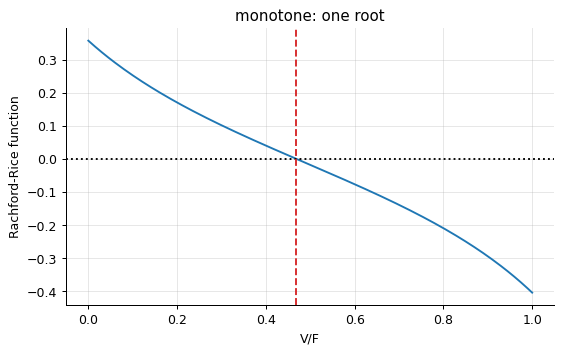

In [3]:
T = 0.5 * (Tb + Td)
res = flash.flash_TP(names, z, T, P)
print(f"flash at {T-273.15:.1f} degC: V/F = {res['V_over_F']:.3f}")
print(pd.DataFrame({"component": names, "z": z, "K": np.round(res["K"], 3), "x (liquid)": np.round(res["x"], 3), "y (vapour)": np.round(res["y"], 3)}).to_string(index=False))
psi = np.linspace(0, 1, 200)
f = [np.sum(np.array(z) * (res["K"] - 1) / (1 + p * (res["K"] - 1))) for p in psi]
plt.plot(psi, f); plt.axhline(0, color="k", ls=":"); plt.axvline(res["V_over_F"], color="C3", ls="--"); plt.xlabel("V/F"); plt.ylabel("Rachford-Rice function"); plt.title("monotone: one root"); plt.show()

Rachford and Rice combined the component balances into one equation in the vapour fraction, monotone
between the poles, so a root finder cannot miss. One flash enriches the vapour in butane from 30 to 45 %:
useful, but nowhere near a separation. Columns exist because one stage is not enough.

## Flash curve and the T-V/F diagram

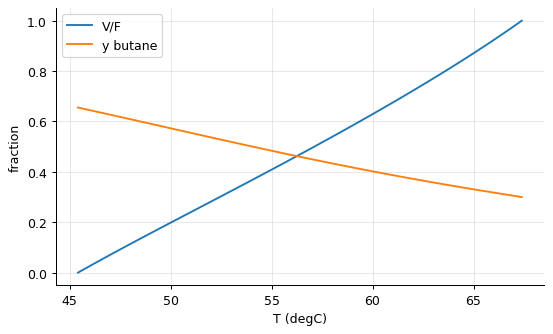

In [4]:
Ts = np.linspace(Tb, Td, 50)
VF = [flash.flash_TP(names, z, T_, P)["V_over_F"] for T_ in Ts]
yC4 = [flash.flash_TP(names, z, T_, P)["y"][0] for T_ in Ts]
fig, ax = plt.subplots(); ax.plot(Ts - 273.15, VF, label="V/F"); ax.plot(Ts - 273.15, yC4, label="y butane"); ax.set(xlabel="T (degC)", ylabel="fraction"); ax.legend(); plt.show()

As the temperature rises through the two-phase region the vapour fraction goes from 0 to 1 and the vapour
gets *leaner* in the light component: the first bubble is the richest vapour the mixture can produce, the last
drop the leanest liquid. A flash trades recovery for purity, and the flash curve is the trade.

## Adiabatic flash: the pressure drop pays for the vapour

In [5]:
cp = [140.0, 167.0, 195.0]                                          # J/(mol K), liquid
dH = [22.4e3, 25.8e3, 28.9e3]                                        # J/mol
for P_flash in (1.5e5, 1.0e5, 0.5e5):
    ad = flash.adiabatic_flash(names, z, T_feed=Tb, P=P_flash, cp_liquid=cp, dH_vap=dH)
    print(f"liquid at its 2 bar bubble point ({Tb-273.15:.1f} degC) flashed to {P_flash/1e5:.1f} bar: T = {ad['T']-273.15:.1f} degC, V/F = {ad['V_over_F']:.3f}")

liquid at its 2 bar bubble point (45.4 degC) flashed to 1.5 bar: T = 37.1 degC, V/F = 0.058
liquid at its 2 bar bubble point (45.4 degC) flashed to 1.0 bar: T = 26.3 degC, V/F = 0.134
liquid at its 2 bar bubble point (45.4 degC) flashed to 0.5 bar: T = 10.1 degC, V/F = 0.246


Throttling a hot liquid through a valve makes vapour at the expense of the liquid's own sensible heat: the
temperature falls until the enthalpy balance closes. The adiabatic flash couples the energy balance to the
phase split - a root find within a root find - and it is how refinery feeds, LNG and refrigerants are
partially vaporised without a heater.

## Binary flash on the x-y diagram

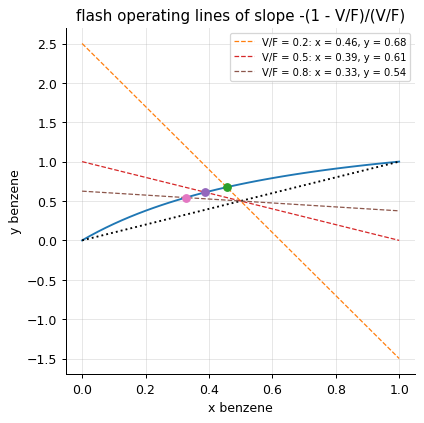

In [6]:
pair, z1 = ("benzene", "toluene"), 0.5
xy = vle.xy(pair, n=41, ideal=True)
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(xy["x"], xy["y"]); ax.plot([0, 1], [0, 1], "k:")
for VF_ in (0.2, 0.5, 0.8):
    T_ = __import__("scipy").optimize.brentq(lambda T: flash.flash_TP(list(pair), [z1, 1 - z1], T, 101325.0)["V_over_F"] - VF_, vle.bubble_T(pair, z1, ideal=True), vle.dew_T(pair, z1, ideal=True))
    r = flash.flash_TP(list(pair), [z1, 1 - z1], T_, 101325.0)
    xline = np.linspace(0, 1, 2); ax.plot(xline, -(1 - VF_) / VF_ * (xline - z1) + z1, "--", lw=1, label=f"V/F = {VF_}: x = {r['x'][0]:.2f}, y = {r['y'][0]:.2f}")
    ax.plot(r["x"][0], r["y"][0], "o")
ax.set(xlabel="x benzene", ylabel="y benzene", title="flash operating lines of slope -(1 - V/F)/(V/F)"); ax.legend(fontsize=8); plt.show()

On the x-y diagram a flash is a straight line through $(z, z)$ with slope $-(1 - \psi)/\psi$: vertical for
$\psi$ = 0 (bubble point), horizontal for $\psi$ = 1 (dew point); its intersection with the equilibrium curve
is the product pair. The same geometry - operating line meets equilibrium curve - is the McCabe-Thiele method
of the next notebook, applied stage after stage.

## Inside the algorithm: Rachford-Rice by bisection

In [7]:
zz, KK = np.array(z), res["K"]
lo, hi = 0.0, 1.0
for _ in range(60):
    mid = 0.5 * (lo + hi)
    if np.sum(zz * (KK - 1) / (1 + mid * (KK - 1))) > 0:
        lo = mid
    else:
        hi = mid
print("by hand: V/F =", round(mid, 6), "; library:", round(res["V_over_F"], 6))

by hand: V/F = 0.468962 ; library: 0.468962


## Exercises
1. A natural-gas liquid (methane... use propane 0.5, n-butane 0.3, n-pentane 0.2) is flashed at 25 degC. Find the pressure range over which it is two-phase and the vapour fraction at 5 bar. What pressure recovers 90 % of the propane in the vapour?
2. Two flashes in series (the liquid from the first flashed again at a lower pressure) versus one flash to the final pressure: compare the purity of the combined vapour for the C4/C5/C6 feed. Why does staging help?
3. **Implement it yourself:** write the dew-point temperature equation (sum y_i/K_i = 1) and solve it with brentq for the C4/C5/C6 feed at 2 bar; compare with `flash.dew_point_T`.